# IndiGo Quarterly EBITDA Margin Forecast ? Full Model Comparison

**Designated final model: SARIMAX.** This notebook compares SARIMAX with all previously trained models and benchmarks. SARIMAX remains the final project model by requirement; validation and holdout metrics show each model's measured performance transparently.

The data contains 38 quarterly observations, so the results are exploratory. The final test period is held out from fitting and model selection.


In [1]:
import os
import pickle
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")
possible_paths = ["/content/EDA ANALYSIS.xlsx", "EDA ANALYSIS.xlsx", "/mnt/data/EDA ANALYSIS.xlsx"]
DATA_PATH = next((p for p in possible_paths if os.path.exists(p)), None)
if DATA_PATH is None:
    raise FileNotFoundError("Place EDA ANALYSIS.xlsx beside this notebook or upload it to Colab.")
df = pd.read_excel(DATA_PATH, sheet_name="Sheet1")
if {"Year", "Quarter (Calendar)"}.issubset(df.columns):
    df = df.sort_values(["Year", "Quarter (Calendar)"]).reset_index(drop=True)

target_col = "EBITDA Margin"
macro_cols = ["USD INR (Quarterly Mean)", "Oil benchmark(MONTHLY) (Quarterly Mean)", "CPI inflation (Quarterly Mean)", "WPI inflation (Quarterly Mean)"]
feature_cols = [target_col] + macro_cols
missing = [c for c in feature_cols if c not in df.columns]
if missing: raise ValueError(f"Missing required columns: {missing}")
work = df[feature_cols].apply(pd.to_numeric, errors="coerce")
work["Target_Next_Q_EBITDA"] = work[target_col].shift(-1)
work["Seasonal_Naive"] = work[target_col].shift(3)
work = work.dropna().reset_index(drop=True)
X = work[feature_cols].astype(float)
X_sarimax = work[macro_cols].astype(float)
y = work["Target_Next_Q_EBITDA"].astype(float)
print(f"Raw quarters: {len(df)} | Usable one-step forecasts: {len(work)}")
display(work[["Target_Next_Q_EBITDA", "Seasonal_Naive"]].head())


Raw quarters: 38 | Usable one-step forecasts: 34


,Target_Next_Q_EBITDA,Seasonal_Naive
0,13.951083,15.000185
1,16.049287,15.000185
2,2.238998,10.478136
3,-0.170010,19.068882
4,-10.825468,13.951083


## Chronological split and candidate models

The earliest 60% is used for training, the next 20% for validation, and the latest 20% for a one-time holdout comparison. The feature-based models use current-quarter financial and macro inputs to predict next-quarter EBITDA Margin. SARIMAX uses the same macroeconomic exogenous inputs. Seasonal Naive, historical mean, and ETS are retained as statistical baselines.


In [2]:
n = len(work)
if n < 15: raise ValueError("Too few quarterly observations for this chronological split.")
train_end, val_end = int(n * .60), int(n * .80)
X_train, X_val, X_test = X.iloc[:train_end], X.iloc[train_end:val_end], X.iloc[val_end:]
Xm_train, Xm_val, Xm_test = X_sarimax.iloc[:train_end], X_sarimax.iloc[train_end:val_end], X_sarimax.iloc[val_end:]
y_train, y_val, y_test = y.iloc[:train_end], y.iloc[train_end:val_end], y.iloc[val_end:]
seasonal_val = work["Seasonal_Naive"].iloc[train_end:val_end].to_numpy()
seasonal_test = work["Seasonal_Naive"].iloc[val_end:].to_numpy()
mean_val = np.repeat(y_train.mean(), len(y_val))
mean_test = np.repeat(y.iloc[:val_end].mean(), len(y_test))

candidate_models = {
    "Ridge": Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=1.0))]),
    "Lasso": Pipeline([("scaler", StandardScaler()), ("model", Lasso(alpha=.1, max_iter=10000))]),
    "Elastic Net": Pipeline([("scaler", StandardScaler()), ("model", ElasticNet(alpha=.1, l1_ratio=.5, max_iter=10000))]),
    "Random Forest": RandomForestRegressor(n_estimators=200, max_depth=2, min_samples_leaf=2, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, max_depth=1, learning_rate=.03, random_state=42)
}
try:
    from xgboost import XGBRegressor
    candidate_models["XGBoost"] = XGBRegressor(n_estimators=100, max_depth=1, learning_rate=.03, subsample=.8, colsample_bytree=.8, objective="reg:squarederror", random_state=42, verbosity=0)
except ImportError:
    print("XGBoost is not installed; remaining models will still run.")

def fit_sarimax(endog, exog):
    return SARIMAX(endog, exog=exog, order=(1,0,0), seasonal_order=(0,0,0,4), trend="c", enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)

validation_predictions = {"Seasonal Naive": seasonal_val, "Historical Mean": mean_val}
for name, model in candidate_models.items():
    model.fit(X_train, y_train)
    validation_predictions[name] = np.asarray(model.predict(X_val)).reshape(-1)
ets_val_model = ExponentialSmoothing(y_train.astype(float), trend="add", seasonal=None, initialization_method="estimated").fit()
validation_predictions["ETS"] = np.asarray(ets_val_model.forecast(len(y_val)))
sarimax_val_model = fit_sarimax(y_train, Xm_train)
validation_predictions["SARIMAX (FINAL MODEL)"] = np.asarray(sarimax_val_model.get_forecast(len(y_val), exog=Xm_val).predicted_mean)

def metric_row(actual, pred, scale):
    mae = mean_absolute_error(actual, pred)
    return {"MAE": mae, "RMSE": np.sqrt(mean_squared_error(actual, pred)), "MASE": mae/scale if scale and np.isfinite(scale) else np.nan}
scale_errors = np.abs(y_train.to_numpy()[4:] - y_train.to_numpy()[:-4])
mase_scale = scale_errors.mean() if len(scale_errors) else np.nan
validation_results = pd.DataFrame([{"Model": k, **metric_row(y_val, v, mase_scale)} for k,v in validation_predictions.items()])
validation_results["Role"] = np.where(validation_results["Model"] == "SARIMAX (FINAL MODEL)", "FINAL MODEL", "Comparator")
validation_results["RoleOrder"] = (validation_results["Role"] != "FINAL MODEL").astype(int)
validation_results = validation_results.sort_values(["RoleOrder", "MAE"]).drop(columns="RoleOrder").reset_index(drop=True)
validation_results = validation_results[["Role", "Model", "MAE", "RMSE", "MASE"]]
print("VALIDATION COMPARISON (SARIMAX is the designated final model)")
display(validation_results.round(3))
print("Designated final model: SARIMAX")


XGBoost is not installed; remaining models will still run.


VALIDATION COMPARISON (SARIMAX is the designated final model)


,Role,Model,MAE,RMSE,MASE
0,FINAL MODEL,SARIMAX (FINAL MODEL),4.953,6.307,0.297
1,Comparator,Seasonal Naive,7.470,8.187,0.448
2,Comparator,Lasso,10.074,10.978,0.604
3,Comparator,Elastic Net,13.264,14.069,0.796
4,Comparator,Ridge,13.278,14.064,0.796
5,Comparator,Gradient Boosting,14.795,15.988,0.887
6,Comparator,Random Forest,16.635,17.735,0.998
7,Comparator,Historical Mean,16.876,17.931,1.012
8,Comparator,ETS,19.370,20.358,1.162


Designated final model: SARIMAX


## Holdout comparison: every model and the final-model graph

Each candidate is refit on train plus validation observations and evaluated on the untouched test period. The graph includes every model with available predictions. SARIMAX is highlighted as the designated final model; the benchmark remains visible for context.


FINAL HOLDOUT TEST RESULTS (SARIMAX is the designated final model)


,Role,Model,MAE,RMSE,MASE
0,FINAL MODEL,SARIMAX (FINAL MODEL),14.197,15.193,0.851
1,Comparator,Seasonal Naive,3.948,4.714,0.237
2,Comparator,ETS,6.612,6.973,0.397
3,Comparator,Random Forest,7.188,7.896,0.431
4,Comparator,Gradient Boosting,8.207,8.841,0.492
5,Comparator,Elastic Net,11.562,12.334,0.693
6,Comparator,Ridge,12.612,13.527,0.756
7,Comparator,Lasso,13.752,14.881,0.825
8,Comparator,Historical Mean,14.853,16.083,0.891


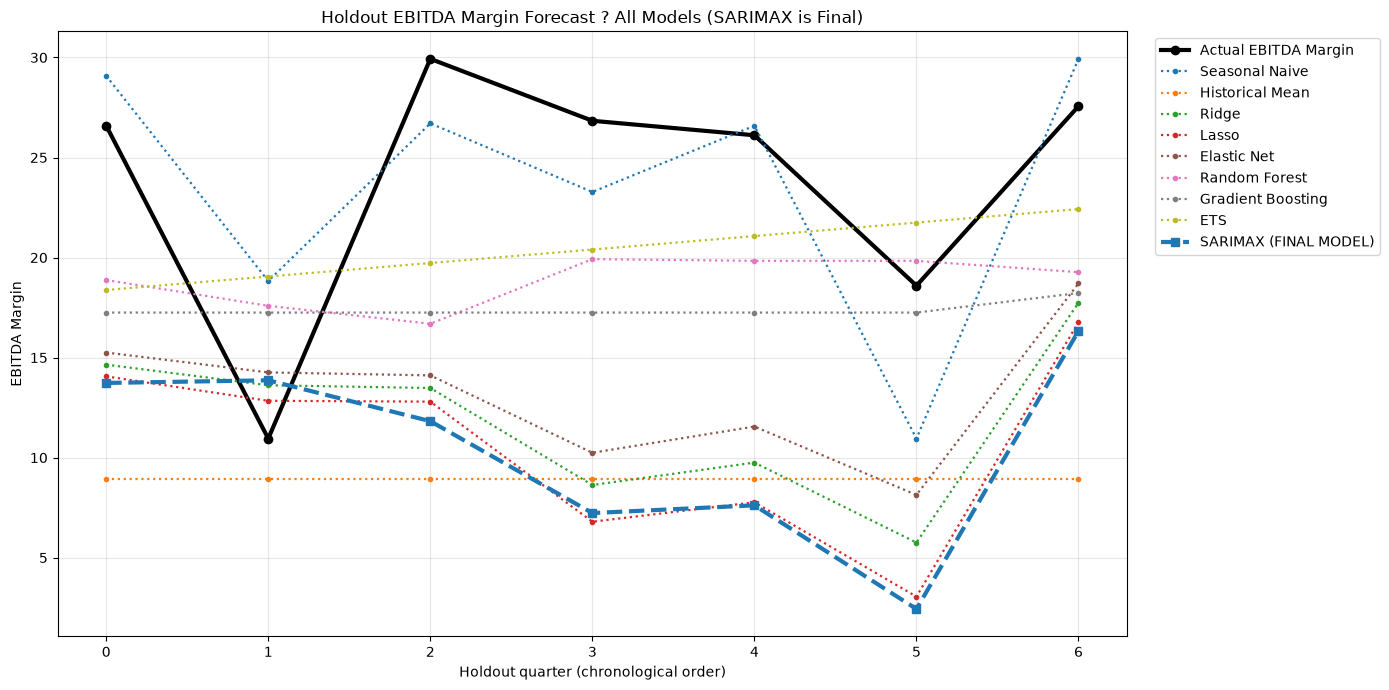

In [3]:
X_trainval, Xm_trainval, y_trainval = X.iloc[:val_end], X_sarimax.iloc[:val_end], y.iloc[:val_end]
test_predictions = {"Seasonal Naive": seasonal_test, "Historical Mean": mean_test}
for name, model in candidate_models.items():
    model.fit(X_trainval, y_trainval)
    test_predictions[name] = np.asarray(model.predict(X_test)).reshape(-1)
ets_full = ExponentialSmoothing(y_trainval.astype(float), trend="add", seasonal=None, initialization_method="estimated").fit()
test_predictions["ETS"] = np.asarray(ets_full.forecast(len(y_test)))
sarimax_test_model = fit_sarimax(y_trainval, Xm_trainval)
test_predictions["SARIMAX (FINAL MODEL)"] = np.asarray(sarimax_test_model.get_forecast(len(y_test), exog=Xm_test).predicted_mean)
test_results = pd.DataFrame([{"Model": k, **metric_row(y_test, v, mase_scale)} for k,v in test_predictions.items()])
test_results["Role"] = np.where(test_results["Model"] == "SARIMAX (FINAL MODEL)", "FINAL MODEL", "Comparator")
test_results["RoleOrder"] = (test_results["Role"] != "FINAL MODEL").astype(int)
test_results = test_results.sort_values(["RoleOrder", "MAE"]).drop(columns="RoleOrder").reset_index(drop=True)
test_results = test_results[["Role", "Model", "MAE", "RMSE", "MASE"]]
print("FINAL HOLDOUT TEST RESULTS (SARIMAX is the designated final model)")
display(test_results.round(3))

plt.figure(figsize=(14, 7))
pos = np.arange(len(y_test))
plt.plot(pos, y_test.to_numpy(), marker="o", linewidth=3, color="black", label="Actual EBITDA Margin")
colors = plt.cm.tab10(np.linspace(0, 1, len(test_predictions)))
for (name, pred), color in zip(test_predictions.items(), colors):
    is_final = name == "SARIMAX (FINAL MODEL)"
    plt.plot(pos, pred, marker="s" if is_final else ".", linestyle="--" if is_final else ":", linewidth=3 if is_final else 1.6, color="tab:blue" if is_final else color, label=name)
plt.title("Holdout EBITDA Margin Forecast ? All Models (SARIMAX is Final)")
plt.xlabel("Holdout quarter (chronological order)")
plt.ylabel("EBITDA Margin")
plt.grid(alpha=.3)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


## Refit the designated final SARIMAX model and forecast

SARIMAX remains the final project model, while the table and graph report each model's measured performance. The final artifact is refit on all available observations.


In [4]:
final_model = fit_sarimax(y, X_sarimax)
artifact = {"model_name": "SARIMAX", "order": (1,0,0), "seasonal_order": (0,0,0,4), "exogenous_columns": macro_cols, "target": "next_quarter_EBITDA_Margin", "forecast_horizon": "1 quarter", "test_metrics": test_results.to_dict(orient="records")}
with open("final_sarimax_ebitda_model.pkl", "wb") as f: pickle.dump({**artifact, "model": final_model}, f)
latest_exog = df[macro_cols].apply(pd.to_numeric, errors="coerce").iloc[[-1]]
if latest_exog.isna().any().any(): raise ValueError("Latest-quarter macro inputs are missing; SARIMAX needs them for the next-quarter forecast.")
next_forecast = float(final_model.get_forecast(steps=1, exog=latest_exog).predicted_mean.iloc[0])
print("FINAL MODEL: SARIMAX")
print(f"Next-quarter EBITDA Margin forecast: {next_forecast:.2f}")
print("Saved artifact: final_sarimax_ebitda_model.pkl")


FINAL MODEL: SARIMAX
Next-quarter EBITDA Margin forecast: 21.75
Saved artifact: final_sarimax_ebitda_model.pkl


## Notes

- SARIMAX is explicitly designated as the final model, regardless of which model has the lowest displayed error.
- Validation and holdout tables show actual MAE, RMSE, and MASE for SARIMAX, Ridge, Lasso, Elastic Net, Random Forest, Gradient Boosting, XGBoost when available, ETS, Seasonal Naive, and Historical Mean.
- The graph compares all available holdout predictions with actual EBITDA Margin.
- The dataset is small; metrics and model rankings are provisional and should be refreshed when new quarters are available.
- The forecast assumes the latest macroeconomic inputs are known at the forecast origin.
